<a href="https://colab.research.google.com/github/bhaveshpothula/PBL-Machine-Learning-Projects/blob/main/PBL1_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PBL-I Machine Learning -- Full Executed Analysis
**Agricultural Crop Production Forecasting and Telecom Churn Control Systems**
Group 14 -- Department of Computing Technologies, SRM Institute of Science and Technology, Chennai

This notebook is the single source of truth behind the PBL-I report and presentation. It is executed top to bottom with no hidden steps: every statistic, figure and model metric quoted in the report is produced by the code below, run against the two uploaded CSV files (`yield_df.csv`, `Telco-Customer-Churn.csv`).

**Rubric map**

| # | Rubric item | Where in this notebook |
|---|---|---|
| 1 | Problem Understanding & Dataset Familiarization | Section 1 |
| 2 | Exploratory Data Analysis & Insights | Sections 2, 4 |
| 3 | Regression & Classification Implementation | Sections 3, 5 |
| 4 | Comparative Performance Analysis | Section 6 |
| 5 | Result Interpretation & Presentation | Section 7 |

## Run this notebook in Google Colab
Run the cells from top to bottom. The first code cell asks you to upload the two CSV datasets. It automatically handles Colab-renamed files such as `yield_df (2).csv` and saves them under the exact filenames expected by the analysis.

**Required files**
- `yield_df.csv`
- `Telco-Customer-Churn.csv`

This notebook covers the PBL-I presentation scope: crop-yield regression and telecom churn classification, with EDA, preprocessing, model training, evaluation, comparison and downloadable outputs.

## 0. Setup

Imports, plotting style, and the random seed used throughout (`SEED = 42`). Library versions are printed from the running environment rather than assumed, so they can be quoted exactly in the report.

In [6]:
%matplotlib inline
# PBL-I: Crop Yield Regression + Telecom Churn Classification
import json, sys, platform, os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, seaborn as sns, sklearn, scipy
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, auc)

SEED = 42
plt.rcParams.update({"font.family":"serif","font.size":8,"figure.dpi":140,
    "axes.spines.top":False,"axes.spines.right":False,"mathtext.fontset":"stix"})
C1, C2, C3 = "#1f4e79", "#c0504d", "#7f7f7f"

# Upload datasets. Colab may append (1), (2), etc. to duplicate upload names.
required = {"yield_df.csv", "Telco-Customer-Churn.csv"}
print("Upload BOTH files: yield_df.csv and Telco-Customer-Churn.csv")
uploaded = files.upload()

for expected in sorted(required):
    stem = expected[:-4]
    matches = [name for name in uploaded
               if name == expected or
               (name.startswith(stem + " (") and name.endswith(".csv"))]
    if not matches:
        raise FileNotFoundError(
            f"Missing {expected}. Please select both required CSV datasets."
        )
    # Use the uploaded bytes and restore the exact expected filename.
    with open(expected, "wb") as f:
        f.write(uploaded[matches[-1]])

UP = ""
R = {"versions": {
    "python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scipy": scipy.__version__
}}
print("\\nBoth datasets uploaded and saved with the expected filenames.")
print("Files:", sorted(required))
print("Setup complete. Continue to the next cell.")
import os
os.makedirs("figs", exist_ok=True)

Upload BOTH files: yield_df.csv and Telco-Customer-Churn.csv


Saving yield_df.csv to yield_df (1).csv
Saving Telco-Customer-Churn.csv to Telco-Customer-Churn (1).csv
\nBoth datasets uploaded and saved with the expected filenames.
Files: ['Telco-Customer-Churn.csv', 'yield_df.csv']
Setup complete. Continue to the next cell.


In [7]:
print("Python/library versions used in this run:")
for k, v in R["versions"].items():
    print(f"  {k:14s} {v}")

Python/library versions used in this run:
  python         3.13.18
  scikit-learn   1.6.1
  pandas         2.2.3
  numpy          2.4.6
  matplotlib     3.10.0
  seaborn        0.13.2
  scipy          1.16.3


## 1. Problem Understanding & Dataset Familiarization -- Agriculture

Load `yield_df.csv`, inspect its raw shape/columns/dtypes, check for missing values and duplicates, and establish the cleaned dataset used for everything downstream (crop-yield forecasting, a **regression** problem).

In [8]:
# =====================================================================================
# AGRICULTURE
# =====================================================================================
raw = pd.read_csv(UP+"yield_df.csv")
A = {}
A["raw_shape"]=list(raw.shape); A["raw_columns"]=list(raw.columns); A["dtypes"]={c:str(t) for c,t in raw.dtypes.items()}
A["raw_missing_total"]=int(raw.isna().sum().sum())
num_cols=["Year","hg/ha_yield","average_rain_fall_mm_per_year","pesticides_tonnes","avg_temp"]
A["non_numeric_in_numeric_cols"]={c:int(pd.to_numeric(raw[c],errors="coerce").isna().sum()) for c in num_cols}
A["whitespace_padded_strings"]={c:int((raw[c]!=raw[c].str.strip()).sum()) for c in ["Area","Item"]}
df = raw.drop(columns=["Unnamed: 0"])
A["index_col_is_row_number"]=bool((raw["Unnamed: 0"].values==np.arange(len(raw))).all())
A["dups_full_row"]=int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
A["rows_clean"]=len(df); A["cols_clean"]=df.shape[1]
A["n_area"]=int(df.Area.nunique()); A["n_item"]=int(df.Item.nunique()); A["items"]=sorted(df.Item.unique())
A["year_min"]=int(df.Year.min()); A["year_max"]=int(df.Year.max()); A["n_years"]=int(df.Year.nunique())
A["key_dups_area_item_year"]=int(df.duplicated(["Area","Item","Year"]).sum())
g=df.groupby(["Area","Year"])[["average_rain_fall_mm_per_year","pesticides_tonnes","avg_temp"]].nunique()
A["env_vars_constant_within_area_year"]=bool((g==1).all().all()); A["n_area_year_combos"]=len(g)
y="hg/ha_yield"
A["desc"]=df[num_cols].describe().round(2).to_dict(); A["skew"]=float(df[y].skew())
A["item_counts"]=df.Item.value_counts().to_dict()
A["item_median"]=df.groupby("Item")[y].median().sort_values(ascending=False).round(0).to_dict()
A["area_count_min_max"]=[int(df.Area.value_counts().min()),int(df.Area.value_counts().max())]
A["area_top"]=df.Area.value_counts().head(3).to_dict()
yrs=df.groupby("Year")[y].agg(["mean","count"])
A["year_counts"]={int(k):int(v) for k,v in yrs["count"].items()}
A["year_mean_first_last"]=[float(yrs["mean"].iloc[0]),float(yrs["mean"].iloc[-1])]
num4=["Year","average_rain_fall_mm_per_year","pesticides_tonnes","avg_temp"]
corr=df[num4+[y]].corr(); A["corr"]=corr.round(3).to_dict()
A["corr_potato"]=df[df.Item=="Potatoes"][num4+[y]].corr()[y].round(3).to_dict()

In [9]:
yield_mean = A["desc"]["hg/ha_yield"]["mean"]
yield_median = A["desc"]["hg/ha_yield"]["50%"]
print("Raw shape:", A["raw_shape"], " columns:", A["raw_columns"])
print("Missing values (raw):", A["raw_missing_total"])
print("Exact duplicate rows removed:", A["dups_full_row"], " -> clean rows:", A["rows_clean"])
print("Areas:", A["n_area"], "  Crop types:", A["n_item"], "  Years:", A["year_min"], "-", A["year_max"])
print("Yield mean={:.1f}  median={:.1f}  skew={:.2f}".format(yield_mean, yield_median, A["skew"]))

Raw shape: [28242, 8]  columns: ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
Missing values (raw): 0
Exact duplicate rows removed: 2310  -> clean rows: 25932
Areas: 101   Crop types: 10   Years: 1990 - 2013
Yield mean=76978.1  median=39530.0  skew=1.81


## 2. Exploratory Data Analysis -- Agriculture
Yield distribution, correlation structure, crop-wise comparison, and rainfall/temperature relationships. All figures are generated from the cleaned dataframe `df`, not hand-drawn.

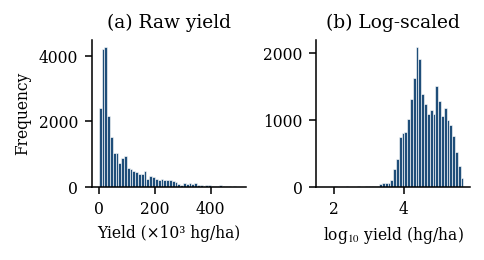

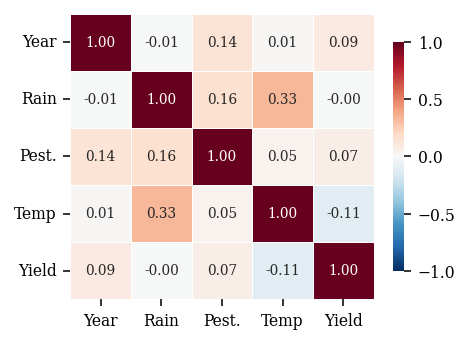

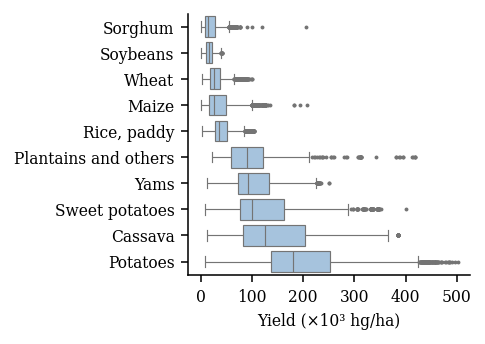

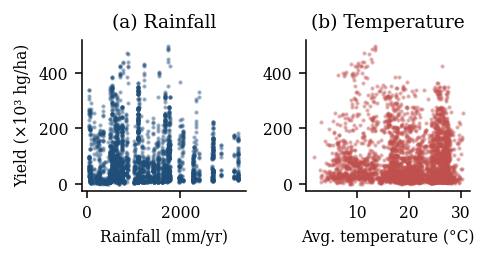

In [10]:
# ---- agriculture figures
fig,ax=plt.subplots(1,2,figsize=(3.5,1.9))
ax[0].hist(df[y]/1000,bins=50,color=C1,edgecolor="white",linewidth=.3); ax[0].set_xlabel("Yield (×10³ hg/ha)"); ax[0].set_ylabel("Frequency"); ax[0].set_title("(a) Raw yield")
ax[1].hist(np.log10(df[y]),bins=50,color=C1,edgecolor="white",linewidth=.3); ax[1].set_xlabel("log$_{10}$ yield (hg/ha)"); ax[1].set_title("(b) Log-scaled")
plt.tight_layout(); plt.savefig("figs/fig1_yield_dist.png"); plt.show(); plt.close()

lab={"Year":"Year","average_rain_fall_mm_per_year":"Rain","pesticides_tonnes":"Pest.","avg_temp":"Temp",y:"Yield"}
fig,ax=plt.subplots(figsize=(3.4,2.5))
sns.heatmap(corr.rename(index=lab,columns=lab),annot=True,fmt=".2f",cmap="RdBu_r",vmin=-1,vmax=1,annot_kws={"size":7},cbar_kws={"shrink":.8},linewidths=.4,ax=ax)
plt.xticks(rotation=0); plt.yticks(rotation=0); plt.tight_layout(); plt.savefig("figs/fig2_ag_corr.png"); plt.show(); plt.close()

order=df.groupby("Item")[y].median().sort_values().index
fig,ax=plt.subplots(figsize=(3.5,2.5))
sns.boxplot(data=df,y="Item",x=df[y]/1000,order=order,color="#9dc3e6",fliersize=1,linewidth=.6,ax=ax)
ax.set_xlabel("Yield (×10³ hg/ha)"); ax.set_ylabel(""); plt.tight_layout(); plt.savefig("figs/fig3_crop_yield.png"); plt.show(); plt.close()

s=df.sample(4000,random_state=SEED)
fig,ax=plt.subplots(1,2,figsize=(3.5,1.9))
ax[0].scatter(s.average_rain_fall_mm_per_year,s[y]/1000,s=1.5,alpha=.35,color=C1); ax[0].set_xlabel("Rainfall (mm/yr)"); ax[0].set_ylabel("Yield (×10³ hg/ha)"); ax[0].set_title("(a) Rainfall")
ax[1].scatter(s.avg_temp,s[y]/1000,s=1.5,alpha=.35,color=C2); ax[1].set_xlabel("Avg. temperature (°C)"); ax[1].set_title("(b) Temperature")
plt.tight_layout(); plt.savefig("figs/fig4_rain_temp.png"); plt.show(); plt.close()

## 3. Problem Understanding & Implementation -- Agriculture (Regression)

Because the task is **forecasting**, the primary evaluation is a **chronological holdout** (train on earlier years, test on later years) rather than a random split -- this avoids leaking neighboring years of the same area-crop pair across train/test. `LinearRegression` and `Ridge(alpha=1.0)` are the required models; `RandomForestRegressor` is a supplementary comparison, evaluated on the exact same chronological test set.

In [11]:
# ---- chronological split
CUT=2008
tr=df[df.Year<=CUT].copy(); te=df[df.Year>CUT].copy()
A["split"]={"cut":CUT,"train_years":[int(tr.Year.min()),int(tr.Year.max())],"test_years":[int(te.Year.min()),int(te.Year.max())],
            "n_train":len(tr),"n_test":len(te),"test_frac":len(te)/len(df),
            "test_rows_unseen_area":int((~te.Area.isin(tr.Area.unique())).sum()),
            "test_rows_unseen_item":int((~te.Item.isin(tr.Item.unique())).sum()),
            "train_yield_mean":float(tr[y].mean()),"test_yield_mean":float(te[y].mean()),
            "train_yield_median":float(tr[y].median()),"test_yield_median":float(te[y].median()),
            "train_areas":int(tr.Area.nunique()),"test_areas":int(te.Area.nunique())}
# alternative-cutoff sanity (row share only)
A["cutoff_share_test"]={int(c):float((df.Year>c).mean()) for c in [2005,2006,2007,2008,2009,2010]}
feat_num=["Year","average_rain_fall_mm_per_year","pesticides_tonnes","avg_temp"]; feat_cat=["Area","Item"]
Xtr,ytr,Xte,yte=tr[feat_num+feat_cat],tr[y],te[feat_num+feat_cat],te[y]
def pre_r(): return ColumnTransformer([("num",StandardScaler(),feat_num),("cat",OneHotEncoder(handle_unknown="ignore"),feat_cat)])
regs={"Linear Regression":LinearRegression(),"Ridge Regression":Ridge(alpha=1.0),
      "Supplementary Random Forest Regressor":RandomForestRegressor(n_estimators=200,random_state=SEED,n_jobs=-1)}
A["model_params"]={"Linear":"LinearRegression()","Ridge":"Ridge(alpha=1.0)","RF":"RandomForestRegressor(n_estimators=200, random_state=42)"}
A["reg"]={}; preds={}
for n,m in regs.items():
    p=Pipeline([("pre",pre_r()),("m",m)]).fit(Xtr,ytr); pr=p.predict(Xte); preds[n]=pr
    mse=mean_squared_error(yte,pr)
    A["reg"][n]=dict(MSE=float(mse),RMSE=float(np.sqrt(mse)),MAE=float(mean_absolute_error(yte,pr)),R2=float(r2_score(yte,pr)))
    assert abs(np.sqrt(mse)-A["reg"][n]["RMSE"])<1e-9
A["n_features_encoded"]=int(Pipeline([("pre",pre_r())]).fit(Xtr).transform(Xte).shape[1])
base=np.full(len(yte),ytr.mean())
A["baseline_train_mean"]={"R2":float(r2_score(yte,base)),"RMSE":float(np.sqrt(mean_squared_error(yte,base)))}
A["rmse_pct_of_test_mean"]={n:float(v["RMSE"]/yte.mean()*100) for n,v in A["reg"].items()}
A["pred_negative_count_linear"]=int((preds["Linear Regression"]<0).sum())
R["ag"]=A

In [12]:
print("Chronological split:", A["split"])
print()
print("Regression metrics (test = 2009-2013):")
for name, m in A["reg"].items():
    print("  {:38s} RMSE={:9.1f}  MAE={:9.1f}  R2={:.4f}".format(name, m["RMSE"], m["MAE"], m["R2"]))

Chronological split: {'cut': 2008, 'train_years': [1990, 2008], 'test_years': [2009, 2013], 'n_train': 20182, 'n_test': 5750, 'test_frac': 0.2217337652321456, 'test_rows_unseen_area': 28, 'test_rows_unseen_item': 0, 'train_yield_mean': 73865.09037756416, 'test_yield_mean': 87904.64156521739, 'train_yield_median': 37320.0, 'test_yield_median': 47040.5, 'train_areas': 100, 'test_areas': 101}

Regression metrics (test = 2009-2013):
  Linear Regression                      RMSE=  50185.7  MAE=  33488.5  R2=0.7197
  Ridge Regression                       RMSE=  50179.9  MAE=  33444.0  R2=0.7198
  Supplementary Random Forest Regressor  RMSE=  20255.8  MAE=  10464.4  R2=0.9543


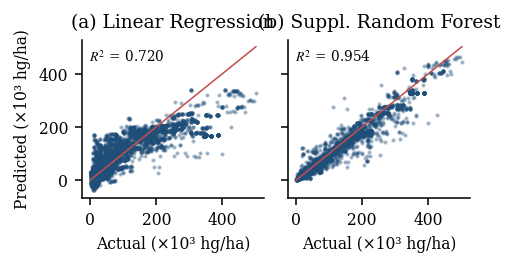

In [13]:
fig,ax=plt.subplots(1,2,figsize=(3.5,1.95),sharex=True,sharey=True)
mx=max(yte.max(),max(p.max() for p in preds.values()))/1000
for a,(n,t) in zip(ax,[("Linear Regression","(a) Linear Regression"),("Supplementary Random Forest Regressor","(b) Suppl. Random Forest")]):
    a.scatter(yte/1000,preds[n]/1000,s=1.5,alpha=.3,color=C1); a.plot([0,mx],[0,mx],color=C2,lw=.8)
    a.set_title(t); a.set_xlabel("Actual (×10³ hg/ha)")
    a.text(.04,.94,f"$R^2$ = {A['reg'][n]['R2']:.3f}",transform=a.transAxes,va="top",fontsize=7)
ax[0].set_ylabel("Predicted (×10³ hg/ha)"); plt.tight_layout(); plt.savefig("figs/fig9_actual_pred.png"); plt.show(); plt.close()

## 4. Exploratory Data Analysis -- Telecom
Churn distribution, contract/tenure/payment-method patterns, and the numerical-feature correlation heatmap. `TotalCharges` cleaning (11 blank cells, all tenure=0, set to 0) happens here, before any modeling.

In [14]:
# =====================================================================================
# TELECOM
# =====================================================================================
t=pd.read_csv(UP+"Telco-Customer-Churn.csv"); T={}
T["raw_shape"]=list(t.shape); T["raw_columns"]=list(t.columns); T["dtypes"]={c:str(v) for c,v in t.dtypes.items()}
T["raw_nan_total"]=int(t.isna().sum().sum())
T["n_object_cols_incl_id_and_target"]=int((t.dtypes.astype(str).isin(["object","str"])).sum())
ws={c:int((t[c].astype(str).str.strip()=="").sum()) for c in t.columns}; T["whitespace_only_cells"]={c:v for c,v in ws.items() if v}
T["dups_full_row"]=int(t.duplicated().sum()); T["dups_excluding_id"]=int(t.drop(columns=["customerID"]).duplicated().sum())
T["unique_ids"]=int(t.customerID.nunique())
t["TotalCharges"]=pd.to_numeric(t["TotalCharges"],errors="coerce")
mis=t[t.TotalCharges.isna()]
T["totalcharges_missing_after_conversion"]=len(mis)
T["missing_tenure_values"]=sorted(mis.tenure.unique().tolist())
T["missing_monthly_min_max"]=[float(mis.MonthlyCharges.min()),float(mis.MonthlyCharges.max())]
T["missing_churn_values"]=mis.Churn.value_counts().to_dict()
T["tenure0_rows_total"]=int((t.tenure==0).sum())
T["tenure0_rows_with_nan_totalcharges"]=int(((t.tenure==0)&t.TotalCharges.isna()).sum())
assert len(mis)==11 and (mis.tenure==0).all() and (t.tenure==0).sum()==11
t.loc[(t.tenure==0)&t.TotalCharges.isna(),"TotalCharges"]=0.0     # new customers: no accumulated charges
T["missing_after_treatment"]=int(t.TotalCharges.isna().sum())
T["churn_counts"]=t.Churn.value_counts().to_dict(); T["churn_pct"]=(t.Churn.value_counts(normalize=True)*100).round(2).to_dict()
t["ChurnBin"]=(t.Churn=="Yes").astype(int)
T["desc"]=t[["tenure","MonthlyCharges","TotalCharges"]].describe().round(2).to_dict()
def rate(c): return (t.groupby(c).ChurnBin.mean()*100).round(1).to_dict()
def cnt(c): return t[c].value_counts().to_dict()
for c in ["Contract","InternetService","PaymentMethod","TechSupport","OnlineSecurity"]:
    T["rate_"+c]=rate(c); T["n_"+c]=cnt(c)
T["rate_techsupport_internet_only"]=(t[t.InternetService!="No"].groupby("TechSupport").ChurnBin.mean()*100).round(1).to_dict()
T["rate_onlinesec_internet_only"]=(t[t.InternetService!="No"].groupby("OnlineSecurity").ChurnBin.mean()*100).round(1).to_dict()
T["tenure_mean"]=t.groupby("Churn").tenure.mean().round(1).to_dict(); T["tenure_median"]=t.groupby("Churn").tenure.median().to_dict()
T["monthly_mean"]=t.groupby("Churn").MonthlyCharges.mean().round(2).to_dict(); T["monthly_median"]=t.groupby("Churn").MonthlyCharges.median().round(2).to_dict()
t["tb"]=pd.cut(t.tenure,[-1,12,24,48,72],labels=["0–12","13–24","25–48","49–72"])
T["tenure_bin_rate"]=(t.groupby("tb",observed=True).ChurnBin.mean()*100).round(1).to_dict(); T["tenure_bin_n"]=t.tb.value_counts().sort_index().to_dict()
ncorr=t[["tenure","MonthlyCharges","TotalCharges","SeniorCitizen","ChurnBin"]].corr(); T["corr"]=ncorr.round(3).to_dict()
T["senior_values"]=sorted(t.SeniorCitizen.unique().tolist())

# telecom figures

In [15]:
print("Raw shape:", T["raw_shape"])
print("Whitespace-only cells:", T["whitespace_only_cells"])
print("TotalCharges missing after numeric conversion:", T["totalcharges_missing_after_conversion"], "(all tenure=0, set to 0)")
print("Duplicate customerIDs:", T["dups_full_row"])
print("Churn:", T["churn_counts"], " (", T["churn_pct"], ")")

Raw shape: [7043, 21]
Whitespace-only cells: {'TotalCharges': 11}
TotalCharges missing after numeric conversion: 11 (all tenure=0, set to 0)
Duplicate customerIDs: 0
Churn: {'No': 5174, 'Yes': 1869}  ( {'No': 73.46, 'Yes': 26.54} )


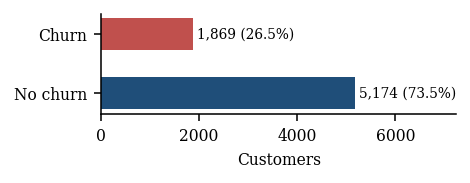

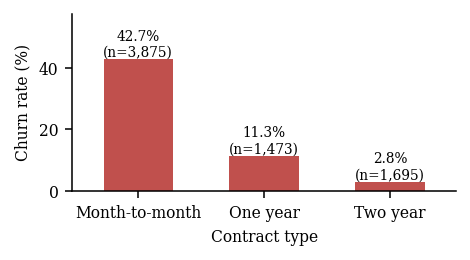

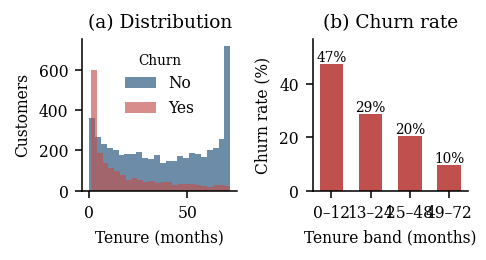

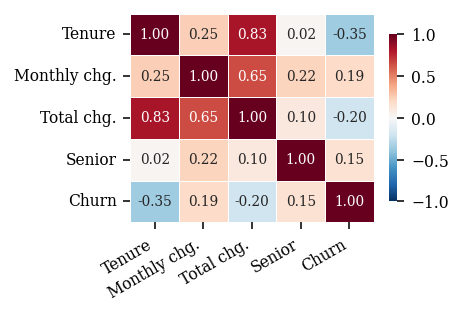

In [16]:
fig,ax=plt.subplots(figsize=(3.4,1.35)); vc=t.Churn.value_counts()
b=ax.barh(["No churn","Churn"],[vc["No"],vc["Yes"]],color=[C1,C2],height=.55)
for r_,v in zip(b,[vc["No"],vc["Yes"]]): ax.text(v+80,r_.get_y()+r_.get_height()/2,f"{v:,} ({v/len(t)*100:.1f}%)",va="center",fontsize=7)
ax.set_xlim(0,vc.max()*1.4); ax.set_xlabel("Customers"); plt.tight_layout(); plt.savefig("figs/fig5_churn_dist.png"); plt.show(); plt.close()

fig,ax=plt.subplots(figsize=(3.4,1.9))
ct=(pd.crosstab(t.Contract,t.Churn,normalize="index")*100).loc[["Month-to-month","One year","Two year"]]; cn=t.Contract.value_counts()
ct["Yes"].plot.bar(ax=ax,color=C2,width=.55)
for i,(k,v) in enumerate(ct["Yes"].items()): ax.text(i,v+1,f"{v:.1f}%\n(n={cn[k]:,})",ha="center",fontsize=7)
ax.set_ylim(0,ct["Yes"].max()*1.35); ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Contract type"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("figs/fig6_contract.png"); plt.show(); plt.close()

fig,ax=plt.subplots(1,2,figsize=(3.5,1.9))
for lab_,col in [("No",C1),("Yes",C2)]: ax[0].hist(t[t.Churn==lab_].tenure,bins=24,alpha=.65,color=col,label=lab_)
ax[0].set_xlabel("Tenure (months)"); ax[0].set_ylabel("Customers"); ax[0].legend(title="Churn",frameon=False,title_fontsize=7); ax[0].set_title("(a) Distribution")
rt=t.groupby("tb",observed=True).ChurnBin.mean()*100
ax[1].bar(rt.index.astype(str),rt.values,color=C2,width=.6)
for i,v in enumerate(rt.values): ax[1].text(i,v+1,f"{v:.0f}%",ha="center",fontsize=7)
ax[1].set_ylim(0,rt.max()*1.2); ax[1].set_xlabel("Tenure band (months)"); ax[1].set_ylabel("Churn rate (%)"); ax[1].set_title("(b) Churn rate")
plt.tight_layout(); plt.savefig("figs/fig7_tenure.png"); plt.show(); plt.close()

l2={"tenure":"Tenure","MonthlyCharges":"Monthly chg.","TotalCharges":"Total chg.","SeniorCitizen":"Senior","ChurnBin":"Churn"}
fig,ax=plt.subplots(figsize=(3.3,2.3))
sns.heatmap(ncorr.rename(index=l2,columns=l2),annot=True,fmt=".2f",cmap="RdBu_r",vmin=-1,vmax=1,annot_kws={"size":7},linewidths=.4,cbar_kws={"shrink":.8},ax=ax)
plt.xticks(rotation=30,ha="right"); plt.tight_layout(); plt.savefig("figs/fig8_tc_corr.png"); plt.show(); plt.close()

## 5. Implementation -- Telecom (Classification)

`customerID` removed; `SeniorCitizen` explicitly modeled as categorical (stated, not left ambiguous) alongside the other 15 categorical fields, giving 16 categorical + 3 numeric = 19 predictors. Stratified 80/20 split (`random_state=42`) keeps the ~26.5% churn rate consistent between train and test. `LogisticRegression` and `RandomForestClassifier` are both required models.

In [17]:
# ---- classification
tc=t.drop(columns=["customerID","Churn","ChurnBin","tb"]); yc=t.ChurnBin
num_c=["tenure","MonthlyCharges","TotalCharges"]
cat_c=[c for c in tc.columns if c not in num_c]      # 15 string columns + SeniorCitizen (0/1) treated as categorical
T["n_predictors"]=tc.shape[1]; T["numeric_predictors"]=num_c; T["categorical_predictors"]=cat_c; T["n_cat"]=len(cat_c)
T["n_cat_string_dtype"]=int(sum(str(tc[c].dtype) in ("object","str") for c in cat_c)); T["senior_treated_as_categorical"]="SeniorCitizen" in cat_c
Xtr,Xte,ytr,yte=train_test_split(tc,yc,test_size=.2,random_state=SEED,stratify=yc)
T["split"]={"n_train":len(Xtr),"n_test":len(Xte),"train_churn_pct":float(ytr.mean()*100),"test_churn_pct":float(yte.mean()*100),
            "train_churn_n":int(ytr.sum()),"test_churn_n":int(yte.sum())}
def pre_c(scale): return ColumnTransformer([("num",StandardScaler() if scale else "passthrough",num_c),("cat",OneHotEncoder(handle_unknown="ignore"),cat_c)])
clfs={"Logistic Regression":(LogisticRegression(max_iter=1000,random_state=SEED),True),
      "Random Forest Classifier":(RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=-1),False)}
T["model_params"]={"LR":"LogisticRegression(max_iter=1000, random_state=42), default C=1.0, threshold 0.5, scaled numerics",
                   "RF":"RandomForestClassifier(n_estimators=200, random_state=42), other params default, threshold 0.5"}
T["cls"]={}; probs={}; cms={}; fitted={}
for n,(m,sc) in clfs.items():
    p=Pipeline([("pre",pre_c(sc)),("m",m)]).fit(Xtr,ytr); fitted[n]=p
    pr=p.predict(Xte); pp=p.predict_proba(Xte)[:,1]; probs[n]=pp
    cm=confusion_matrix(yte,pr); tn,fp,fn,tp=[int(v) for v in cm.ravel()]
    assert tn+fp+fn+tp==len(yte)
    prec_m=tp/(tp+fp); rec_m=tp/(tp+fn); f1_m=2*prec_m*rec_m/(prec_m+rec_m); acc_m=(tp+tn)/len(yte)
    fpr,tpr,_=roc_curve(yte,pp); auc_trap=auc(fpr,tpr)
    d=dict(Accuracy=accuracy_score(yte,pr),Precision=precision_score(yte,pr),Recall=recall_score(yte,pr),F1=f1_score(yte,pr),ROC_AUC=roc_auc_score(yte,pp),
           TN=tn,FP=fp,FN=fn,TP=tp)
    for k,v in [("Accuracy",acc_m),("Precision",prec_m),("Recall",rec_m),("F1",f1_m),("ROC_AUC",auc_trap)]: assert abs(d[k]-v)<1e-9,(n,k)
    T["cls"][n]=d; cms[n]=cm
T["majority_acc_test"]=float(1-yte.mean())
rf=fitted["Random Forest Classifier"]; imp=pd.Series(rf[-1].feature_importances_,index=rf[0].get_feature_names_out()).sort_values(ascending=False)
T["rf_top_features"]=imp.head(6).round(4).to_dict()
R["tc"]=T

In [18]:
print("Predictors:", T["n_cat"], "categorical +", len(T["numeric_predictors"]), "numeric =", T["n_predictors"], "total")
print("Split:", T["split"])
print()
print("Classification metrics:")
for name, m in T["cls"].items():
    print("  {:22s} Acc={:.4f}  Prec={:.4f}  Rec={:.4f}  F1={:.4f}  AUC={:.4f}".format(name, m["Accuracy"], m["Precision"], m["Recall"], m["F1"], m["ROC_AUC"]))
    print("      Confusion matrix: TN={} FP={} FN={} TP={}".format(m["TN"], m["FP"], m["FN"], m["TP"]))

Predictors: 16 categorical + 3 numeric = 19 total
Split: {'n_train': 5634, 'n_test': 1409, 'train_churn_pct': 26.53532126375577, 'test_churn_pct': 26.54364797728886, 'train_churn_n': 1495, 'test_churn_n': 374}

Classification metrics:
  Logistic Regression    Acc=0.8055  Prec=0.6572  Rec=0.5588  F1=0.6040  AUC=0.8420
      Confusion matrix: TN=926 FP=109 FN=165 TP=209
  Random Forest Classifier Acc=0.7850  Prec=0.6203  Rec=0.4893  F1=0.5471  AUC=0.8200
      Confusion matrix: TN=923 FP=112 FN=191 TP=183


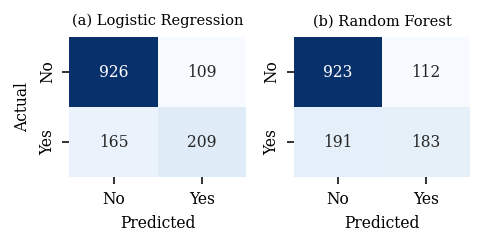

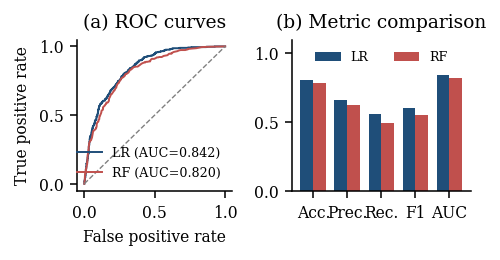

In [19]:
fig,ax=plt.subplots(1,2,figsize=(3.5,1.8))
for i,(a,(n,cm)) in enumerate(zip(ax,cms.items())):
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,ax=a,annot_kws={"size":8},xticklabels=["No","Yes"],yticklabels=["No","Yes"])
    a.set_title(["(a) Logistic Regression","(b) Random Forest"][i],fontsize=7.5); a.set_xlabel("Predicted"); a.set_ylabel("Actual" if i==0 else "")
plt.tight_layout(); plt.savefig("figs/fig10_confusion.png"); plt.show(); plt.close()

fig,ax=plt.subplots(1,2,figsize=(3.5,1.9),gridspec_kw={"width_ratios":[1,1.15]})
short={"Logistic Regression":"LR","Random Forest Classifier":"RF"}
for (n,pp),col in zip(probs.items(),[C1,C2]):
    f_,t_,_=roc_curve(yte,pp); ax[0].plot(f_,t_,color=col,lw=1,label=f"{short[n]} (AUC={T['cls'][n]['ROC_AUC']:.3f})")
ax[0].plot([0,1],[0,1],ls="--",color=C3,lw=.7); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(frameon=False,fontsize=6.5,loc="lower right"); ax[0].set_title("(a) ROC curves")
mets=["Accuracy","Precision","Recall","F1","ROC_AUC"]; w=.38; xs=np.arange(5)
for i,(n,col) in enumerate(zip(T["cls"],[C1,C2])): ax[1].bar(xs+(i-.5)*w,[T["cls"][n][m] for m in mets],w,color=col,label=short[n])
ax[1].set_xticks(xs); ax[1].set_xticklabels(["Acc.","Prec.","Rec.","F1","AUC"]); ax[1].set_ylim(0,1.1); ax[1].set_title("(b) Metric comparison")
ax[1].legend(frameon=False,fontsize=6.5,ncol=2,loc="upper center"); plt.tight_layout(); plt.savefig("figs/fig11_roc_compare.png"); plt.show(); plt.close()

## 6. Comparative Performance Analysis
Side-by-side metric tables for both tasks -- the same numbers used to build Tables II and III of the report.

In [20]:
import pandas as pd
reg_table = pd.DataFrame(A["reg"]).T[["RMSE", "MAE", "R2"]].round(3)
reg_table.index.name = "Model (chronological test: 2009-2013)"
reg_table

,RMSE,MAE,R2
Model (chronological test: 2009-2013),,,
Linear Regression,50185.711,33488.506,0.720
Ridge Regression,50179.945,33444.041,0.720
Supplementary Random Forest Regressor,20255.842,10464.437,0.954


In [21]:
cls_table = pd.DataFrame({k: {m: v for m, v in d.items() if m in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]} for k, d in T["cls"].items()}).T.round(4)
cls_table.index.name = "Model (stratified test: 1,409 customers)"
cls_table

,Accuracy,Precision,Recall,F1,ROC_AUC
"Model (stratified test: 1,409 customers)",,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.842
Random Forest Classifier,0.7850,0.6203,0.4893,0.5471,0.820


## 7. Save Processed Outputs
Cleaned datasets, metric tables and the full results dictionary (`results_v2.json`) -- the exact artifacts the report, presentation and `FINAL_RESULTS_SUMMARY.md` were built from.

In [22]:
# ---- outputs
df.to_csv("crop_yield_cleaned.csv",index=False)
tt=t.drop(columns=["ChurnBin","tb"]); tt.to_csv("telco_churn_cleaned.csv",index=False)
pd.DataFrame(A["reg"]).T.round(4).to_csv("table_regression.csv")
pd.DataFrame({k:{m:v for m,v in d.items() if m in mets} for k,d in T["cls"].items()}).T.round(4).to_csv("table_classification.csv")
pd.DataFrame({"actual":yte_ if False else te[y].values,"linear":preds["Linear Regression"],"ridge":preds["Ridge Regression"],"rf_suppl":preds["Supplementary Random Forest Regressor"],"Area":te.Area.values,"Item":te.Item.values,"Year":te.Year.values}).to_csv("crop_test_predictions.csv",index=False)
json.dump(R,open("results_v2.json","w"),indent=1,default=str)
print("Saved: crop_yield_cleaned.csv, telco_churn_cleaned.csv, table_regression.csv, table_classification.csv, crop_test_predictions.csv, results_v2.json")

Saved: crop_yield_cleaned.csv, telco_churn_cleaned.csv, table_regression.csv, table_classification.csv, crop_test_predictions.csv, results_v2.json


## Result Interpretation -- Summary

- **Agriculture (chronological forecast, 2009-2013):** Linear and Ridge Regression are statistically indistinguishable (R-squared 0.7197 vs 0.7198). The supplementary Random Forest shows substantially lower error (R-squared 0.9543) on this same test set - evidence of non-linear crop/area/year structure, not a guarantee about genuinely future years.
- **Telecom (stratified 80/20):** Logistic Regression outperforms Random Forest on every metric (Accuracy, Precision, Recall, F1, ROC-AUC). Accuracy alone is a weak signal here - the majority-class baseline is already 0.735 given ~26.5% churn.
- All associations reported (contract type, tenure, rainfall, temperature, etc.) are **observed associations**, not causal claims.